In [ ]:
%pip install segmentation_models_pytorch

# Imports and data paths

In [3]:
import random
import gc
from tensorflow.keras import initializers
from tensorflow.keras.layers import Input
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import Dropout 
from tensorflow.keras.layers import Conv2DTranspose
from tensorflow.keras.layers import concatenate

from PIL import Image
from scipy.ndimage import zoom

In [4]:
import os
import gc
import torch
import random
import pandas as pd
import numpy as np
import imageio.v3 as imageio
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from torchinfo import summary
import torch.optim as optim
from tqdm import tqdm

import torchvision.models as models
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

import segmentation_models_pytorch as smp


In [5]:
# Corrected paths
path = ''
train_path = os.path.join(path, '/kaggle/input/severstal-steel-defect-detection/train_images')
test_path = os.path.join(path, '/kaggle/input/severstal-steel-defect-detection/test_images/')
csv_path = os.path.join(path, '/kaggle/input/severstal-steel-defect-detection/train.csv')
mask_path= '/kaggle/input/steel-defect-files-no-usampling-or-augmentation/rle_masks.csv'


train_list_orig = os.listdir(train_path)
#test_list_orig = os.listdir(test_path)

train_list_orig.sort()
#test_list_orig.sort()

# Data preprocessing

In [ ]:
# Load the training CSV
df = pd.read_csv(csv_path)
df = df[df['EncodedPixels'].notnull()]
print('Shape of DataFrame: ', df.shape)

In [ ]:
# Process the DataFrame for defect masks
df2 = pd.DataFrame(index=df.index)
df2['d1'] = ''
df2['d2'] = ''
df2['d3'] = ''
df2['d4'] = ''

df2.loc[df['ClassId'] == 1, 'd1'] = df['EncodedPixels']
df2.loc[df['ClassId'] == 2, 'd2'] = df['EncodedPixels']
df2.loc[df['ClassId'] == 3, 'd3'] = df['EncodedPixels']
df2.loc[df['ClassId'] == 4, 'd4'] = df['EncodedPixels']

df2['ImageId'] = df['ImageId']
df2 = df2[['ImageId', 'd1', 'd2', 'd3', 'd4']]

In [ ]:
# Group by ImageId
df2 = df2.groupby('ImageId').agg({
    'd1': lambda x: ' '.join(filter(None, x)),
    'd2': lambda x: ' '.join(filter(None, x)),
    'd3': lambda x: ' '.join(filter(None, x)),
    'd4': lambda x: ' '.join(filter(None, x))
}).reset_index()

all_images_df = pd.DataFrame({'ImageId': train_list_orig})
df2 = pd.merge(all_images_df, df2, on='ImageId', how='left')
df2[['d1', 'd2', 'd3', 'd4']] = df2[['d1', 'd2', 'd3', 'd4']].fillna('0')


In [ ]:
df2 = df2.drop(columns=['ImageId'])

In [ ]:
df2.head(10)

In [ ]:
def ret_zero(item):
    if item == '':
        return '0'
    else:
        return item

In [ ]:
for col in ['d1', 'd2', 'd3', 'd4']:
    df2[col] = df2[col].apply(lambda item: ret_zero(item))

In [ ]:
df2.head(10)

In [ ]:
df2.to_csv('rle_masks.csv', index=False)

In [ ]:
df2.shape

# Dataloader

In [6]:
masks = pd.read_csv(mask_path)
masks.head(10)

,d1,d2,d3,d4
0,29102 12 29346 24 29602 24 29858 24 30114 24 3...,0,0,0
1,0,0,0,0
2,0,0,0,0
3,0,0,0,0
4,0,0,18661 28 18863 82 19091 110 19347 110 19603 11...,0
5,37607 3 37858 8 38108 14 38359 20 38610 25 388...,0,0,0
6,0,0,0,131973 1 132228 4 132483 6 132738 8 132993 11 ...
7,0,0,229501 11 229741 33 229981 55 230221 77 230468...,0
8,0,0,0,0
9,0,0,0,0


In [7]:
c=[0,0,0,0,0]

indxs=["d1","d2","d3","d4"]
for i in range  (len(masks)):
    ctr=[0,0,0,0,0]
    for j in range (4):
        if masks.loc[i].at[indxs[j]]!='0':
            ctr[j]+=1
    c=np.add(c,ctr)
    if masks.loc[i].at[indxs[0]]=='0'and masks.loc[i].at[indxs[1]]=='0' and masks.loc[i].at[indxs[2]]=='0' and masks.loc[i].at[indxs[3]]=='0':
        c[4]+=1
            
            
print(c)

[ 897  247 5150  801 5902]


In [8]:
inds=[]
for i in range  (len(masks)):
    
    
    if masks.loc[i].at[indxs[0]]=='0'and masks.loc[i].at[indxs[1]]=='0' and masks.loc[i].at[indxs[2]]!='0' and masks.loc[i].at[indxs[3]]=='0':
        inds.append(i)
    if masks.loc[i].at[indxs[0]]=='0'and masks.loc[i].at[indxs[1]]=='0' and masks.loc[i].at[indxs[2]]=='0' and masks.loc[i].at[indxs[3]]=='0':
        inds.append(i)
            
inds=inds[0:6000]
print(len(inds))

6000


In [9]:
filtered_images = [img for i, img in enumerate(train_list_orig) if i not in inds]
filtered_masks =masks.drop(inds)

In [10]:
filtered_masks = filtered_masks.reset_index(drop=True)

In [11]:
c=[0,0,0,0,0]

indxs=["d1","d2","d3","d4"]
for i in filtered_masks.index:
    ctr=[0,0,0,0,0]
    for j in range (4):
        if filtered_masks.loc[i].at[indxs[j]]!='0':
            ctr[j]+=1
    c=np.add(c,ctr)
    if filtered_masks.loc[i].at[indxs[0]]=='0'and filtered_masks.loc[i].at[indxs[1]]=='0' and filtered_masks.loc[i].at[indxs[2]]=='0' and filtered_masks.loc[i].at[indxs[3]]=='0':
        c[4]+=1
            
            
print(c)

[ 897  247 2485  801 2567]


In [12]:
def rle2mask(rle, img_shape):
    height, width = img_shape
    
    if pd.isna(rle) or rle == '' or rle == '0':
        return np.zeros((height, width), dtype=np.uint8)
    
    mask = np.zeros((height * width), dtype=np.uint8)
    
    temp= [int(x) for x in rle.split(' ')]
    starts= np.array(temp[0::2]) - 1
    lengths= np.array(temp[1::2])
    
    for start, length in zip(starts, lengths):
        mask[start: start + length] = 1
        
    mask_2d = mask.reshape((height, width), order='F')
    return mask_2d
 

In [13]:
def get_mask(pframe, index):
    d1 =rle2mask(pframe['d1'][index], (256, 1600))
    d2 =rle2mask(pframe['d2'][index], (256, 1600))
    d3 =rle2mask(pframe['d3'][index], (256, 1600))
    d4 =rle2mask(pframe['d4'][index], (256, 1600))
    
    combined = np.stack([d1, d2, d3, d4], axis=-1)
    return torch.tensor(combined, dtype=torch.float32)

In [14]:
def load_image(image_path):
    # Load image using imageio
    image = imageio.imread(image_path)
    # Convert to uint8
    image = image.astype(np.uint8)
    return torch.tensor(image, dtype=torch.float32)

In [15]:
def overlay_masks_on_image(image_tensor, masks_tensor, mask_colors):
    """
    Overlays masks on an image tensor and displays the result using matplotlib.
    
    Parameters:
    - image_tensor: Tensor of shape (H, W, C) where C is the number of channels (e.g., 3 for RGB)
    - masks_tensor: Tensor of shape (H, W, num_masks) where each channel represents a different mask
    - mask_colors: List of colors for the masks, each as a tuple (R, G, B) in range [0, 1]
    """
    # Move tensors to CPU if they are on GPU
    if image_tensor.is_cuda:
        image_tensor = image_tensor.cpu()
    if masks_tensor.is_cuda:
        masks_tensor = masks_tensor.cpu()

    # Convert tensors to NumPy arrays
    image_np = image_tensor.numpy()
    masks_np = masks_tensor.numpy()
    
    # Normalize the image if necessary
    if image_np.max() > 1.0:  # If the image values are in the range [0, 255]
        image_np = image_np / 255.0  # Normalize to [0, 1]
    
    # Prepare an overlay image
    H, W, C = image_np.shape
    num_masks = masks_np.shape[2]
    overlay_image = np.copy(image_np)
    
    # Check if masks and colors are compatible
    if num_masks != len(mask_colors):
        raise ValueError("Number of masks and number of colors must be the same.")
    
    alpha = 0.5  # Transparency factor
    
    # Overlay each mask
    for i in range(num_masks):
        mask = masks_np[:, :, i]
        color = np.array(mask_colors[i])
        # Create a colored mask
        colored_mask = np.zeros((H, W, C), dtype=np.float32)
        for c in range(C):
            colored_mask[:, :, c] = mask * color[c]
        # Combine with the overlay image
        overlay_image = np.where(colored_mask > 0, alpha * colored_mask + (1 - alpha) * overlay_image, overlay_image)
    
    # Display the image with overlaid masks
    plt.imshow(overlay_image)
    plt.axis('off')  # Hide axes
    plt.show()

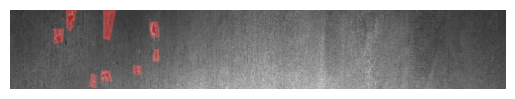

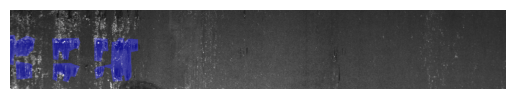

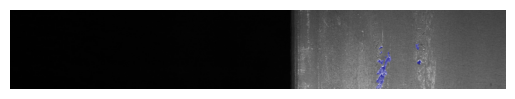

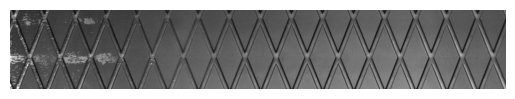

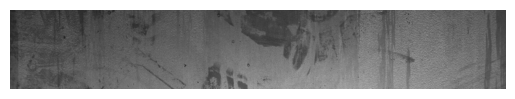

In [16]:
idx = [random.randint(0, len(train_list_orig)) for _ in range(5)]
mask_colors = [(1, 0, 0), (0, 1, 0), (0, 0, 1), (1, 1, 0)]
for ix in idx:
    m= get_mask(masks, ix)
    i= load_image(os.path.join(train_path, train_list_orig[ix]))
    overlay_masks_on_image(i, m, mask_colors)

In [17]:

class CustomImageDataset(Dataset):
    def __init__(self, X, Y, transform=None):
        self.X = X
        self.Y = Y
        self.transform = transform
        
#         a= X
#         a.sort()
#         self.train_list_orig = a


    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        image = load_image(os.path.join('/kaggle/input/severstal-steel-defect-detection/train_images', self.X[idx]))
        masks = get_mask(self.Y, idx)

        if self.transform:
            image = self.transform(image)

        return image, masks
    
    def set_transform(self, transform):
        self.transform = transform


In [18]:
dataset= CustomImageDataset(X = filtered_images, Y = filtered_masks)
train_indices, val_indices = train_test_split(range(len(dataset)), test_size=0.2, random_state=42)

In [19]:
train_dataset = Subset(dataset, train_indices)
val_dataset = Subset(dataset, val_indices)

In [20]:
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=False)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False)

657
Randomly chosen batch: 37
Batch 37
Images shape: torch.Size([8, 256, 1600, 3])
Masks shape: torch.Size([8, 256, 1600, 4])


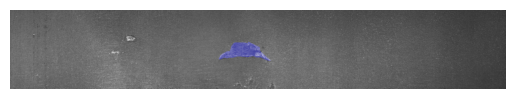

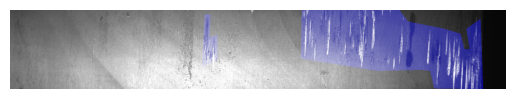

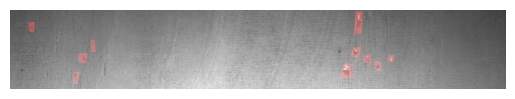

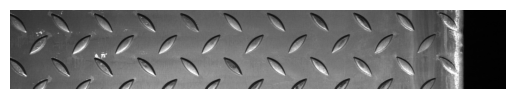

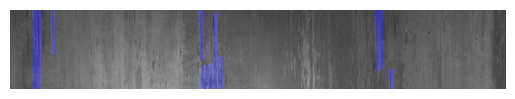

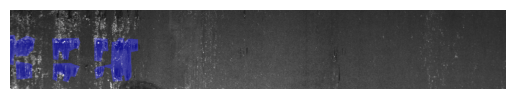

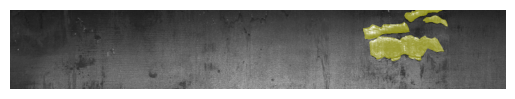

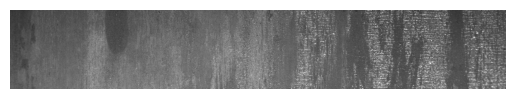

In [21]:
# Example usage: Iterating through the dataloader
print(len(train_loader))
i = random.randint(0, len(train_loader)//10)
print(f'Randomly chosen batch: {i + 1}')
mask_colors = [(1, 0, 0), (0, 1, 0), (0, 0, 1), (1, 1, 0)]
for batch_idx, (image_batch, mask_batch) in enumerate(train_loader):
    if batch_idx == i:
        print(f"Batch {batch_idx+1}")
        print(f"Images shape: {image_batch.shape}")
        print(f"Masks shape: {mask_batch.shape}")
        for img, mask in zip(image_batch, mask_batch):
            overlay_masks_on_image(img, mask, mask_colors)
        break


# Model

In [ ]:
class ResNetEncoder(nn.Module):
    def __init__(self, resnet):
        super(ResNetEncoder, self).__init__()
        # Extract layers from the pretrained ResNet
        self.initial = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool)
        self.encoder1 = resnet.layer1  # Output after 1st block
        self.encoder2 = resnet.layer2  # Output after 2nd block
        self.encoder3 = resnet.layer3  # Output after 3rd block
        self.encoder4 = resnet.layer4  # Output after 4th block

    def forward(self, x):
        x = self.initial(x)
        skip1 = x
        x = self.encoder1(x)
        skip2 = x
        x = self.encoder2(x)
        skip3 = x
        x = self.encoder3(x)
        skip4 = x
        x = self.encoder4(x)
        return x, skip1, skip2, skip3, skip4

In [ ]:
class UpsamplingBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(UpsamplingBlock, self).__init__()
        self.upconv = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
        self.conv1 = nn.Conv2d(out_channels * 2, out_channels, kernel_size=3, padding='same')
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding='same')

    def forward(self, x, skip_connection):
        x = self.upconv(x)
        x = torch.cat([x, skip_connection], dim=1)
        x = self.conv1(x)
        x = self.conv2(x)
        return x

In [ ]:
class UNetResNet(nn.Module):
    def __init__(self, resnet_type='resnet34', num_classes=4, pretrained=True):
        super(UNetResNet, self).__init__()
        # Load the pretrained ResNet model
        resnet = getattr(models, resnet_type)(pretrained=pretrained)
        self.encoder = ResNetEncoder(resnet)

        # Decoder blocks
        self.upsample4 = UpsamplingBlock(512, 256)  # 512 from resnet.layer4, skip4 has 512 channels
        self.upsample3 = UpsamplingBlock(256, 128)  # 256 from resnet.layer3, skip3 has 256 channels
        self.upsample2 = UpsamplingBlock(128, 64)   # 128 from resnet.layer2, skip2 has 128 channels
        self.upsample1 = UpsamplingBlock(64, 64)     # 64 from resnet.layer1, skip1 has 64 channels

        # Final output layer
        self.final_conv = nn.Conv2d(64, num_classes, kernel_size=1)

    def forward(self, x):
        # Encoder forward pass
        x, skip1, skip2, skip3, skip4 = self.encoder(x)
        
        # Decoder with skip connections
        dec4 = self.upsample4(x, skip4)
        dec3 = self.upsample3(dec4, skip3)
        dec2 = self.upsample2(dec3, skip2)
        dec1 = self.upsample1(dec2, skip1)

        out = self.final_conv(dec1)
        return out


In [22]:
class UNetResNet(nn.Module):
    def __init__(self, num_classes=4, encoder_name='resnet50', pretrained=True):
        super(UNetResNet, self).__init__()
        self.unet = smp.Unet(
            encoder_name=encoder_name,
            encoder_weights="imagenet" if pretrained else None,
            in_channels=3,
            classes=num_classes
        )

        self.freeze_encoder()

    def freeze_encoder(self):
        for param in self.unet.encoder.parameters():
            param.requires_grad = False

    def forward(self, x):
        return self.unet(x)

In [ ]:
# U-Net++
class UNetPlusPlusResNet(nn.Module):
    def __init__(self, num_classes=4, encoder_name='resnet34', pretrained=True):
        super(UNetPlusPlusResNet, self).__init__()
        self.unetplusplus = smp.UnetPlusPlus(
            encoder_name=encoder_name,
            encoder_weights="imagenet" if pretrained else None,
            in_channels=3,
            classes=num_classes
        )

        self.freeze_encoder()

    def freeze_encoder(self):
        for param in self.unetplusplus.encoder.parameters():
            param.requires_grad = False

    def forward(self, x):
        return self.unetplusplus(x)


# PSPNet
class PSPNetResNet(nn.Module):
    def __init__(self, num_classes=4, encoder_name='resnet50', pretrained=True):
        super(PSPNetResNet, self).__init__()
        self.pspnet = smp.PSPNet(
            encoder_name=encoder_name,
            encoder_weights="imagenet" if pretrained else None,
            in_channels=3,
            classes=num_classes
        )

        self.freeze_encoder()

    def freeze_encoder(self):
        for param in self.pspnet.encoder.parameters():
            param.requires_grad = False

    def forward(self, x):
        return self.pspnet(x)
    
class FPNResNet(nn.Module):
    def __init__(self, num_classes=4, encoder_name='resnet50', pretrained=True):
        super(FPNResNet, self).__init__()
        self.fpn = smp.FPN(
            encoder_name=encoder_name,
            encoder_weights="imagenet" if pretrained else None,
            in_channels=3,
            classes=num_classes
        )

        self.freeze_encoder()

    def freeze_encoder(self):
        for param in self.fpn.encoder.parameters():
            param.requires_grad = False

    def forward(self, x):
        return self.fpn(x)

In [23]:
model = UNetResNet(num_classes=4)

In [24]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [26]:
# Define the shape for each tensor
shape = (1,224, 1568, 1)  # Shape of each tensor

# Create four tensors of ones
tensor1 = 3*torch.ones(shape)
tensor2 = 8*torch.ones(shape)
tensor3 = torch.ones(shape)
tensor4 = torch.ones(shape)

# Concatenate the tensors along the last dimension (dim=2)
class_weights = torch.cat((tensor1.permute(0, 3, 1, 2), tensor2.permute(0, 3, 1, 2), tensor3.permute(0, 3, 1, 2), tensor4.permute(0, 3, 1, 2)), dim=1)
class_weights = class_weights.to(device)
class_weights.shape


torch.Size([1, 4, 224, 1568])

In [27]:
# Move the model to GPU if available
model.to(device)

# Define loss function and optimizer
criterion = nn.BCEWithLogitsLoss(pos_weight=class_weights)
optimizer = optim.Adam(model.parameters(), lr=0.0004, weight_decay=1e-5)

In [28]:
def compute_dice_coefficient(pred, target, epsilon=1e-6):
    """
    Compute the Dice Coefficient between two binary masks.

    Args:
        pred (torch.Tensor): Predicted binary mask (should be 0 or 1).
        target (torch.Tensor): Ground truth binary mask (should be 0 or 1).
        epsilon (float): Small constant to avoid division by zero.

    Returns:
        float: Dice Coefficient score.
    """
    intersection = torch.sum(pred * target)
    union = torch.sum(pred) + torch.sum(target)
    
    dice = (2. * intersection + epsilon) / (union + epsilon)
    return dice.item()

In [29]:
def compute_miou(pred, target, epsilon=1e-6):
    """
    Compute the Mean Intersection over Union (mIoU) between two binary masks.

    Args:
        pred (torch.Tensor): Predicted binary mask (should be 0 or 1).
        target (torch.Tensor): Ground truth binary mask (should be 0 or 1).
        epsilon (float): Small constant to avoid division by zero.

    Returns:
        float: mIoU score.
    """
    # Intersection: where both pred and target are 1
    intersection = torch.sum(pred * target)
    
    # Union: where pred is 1 or target is 1 (excluding the area of intersection)
    union = torch.sum(pred) + torch.sum(target) - intersection
    
    # Compute mIoU
    miou = (intersection + epsilon) / (union + epsilon)
    
    return miou.item()


In [30]:
from torchvision.transforms import RandomCrop

def input_aug(X, Y):
    crop_height, crop_width = 224, 1568
    original_height, original_width = 256, 1600

    X_aug_list = []
    Y_aug_list = []

    # Initialize the random crop transform
    random_crop = RandomCrop((crop_height, crop_width))

    # Iterate through the batch and apply transformations
    for x, y in zip(X, Y):
        # Ensure x and y are in shape (C, H, W)
        if x.shape[0] != 3:
            x = x.permute(2, 0, 1)  # Convert from (H, W, C) to (C, H, W)
        if y.shape[0] != 4:
            y = y.permute(2, 0, 1)  # Ensure mask is also (C, H, W) format

        # Check if the image size is large enough for the crop
        if x.shape[1] < crop_height or x.shape[2] < crop_width:
            raise ValueError(f"Image size {x.shape[1:]} is smaller than crop size {(crop_height, crop_width)}")

        # Get the parameters for random cropping
        i, j, h, w = random_crop.get_params(x, output_size=(crop_height, crop_width))
        
        # Random crop the images and masks
        x_cropped = TF.crop(x, i, j, h, w)
        y_cropped = TF.crop(y, i, j, h, w)

        # Store the original cropped images and masks
        X_aug_list.append(x_cropped)
        Y_aug_list.append(y_cropped)

        # Apply vertical flip
        X_aug_list.append(TF.vflip(x_cropped))
        Y_aug_list.append(TF.vflip(y_cropped))

        # Apply horizontal flip
        X_aug_list.append(TF.hflip(x_cropped))
        Y_aug_list.append(TF.hflip(y_cropped))

        # Apply both vertical and horizontal flip
        X_aug_list.append(TF.hflip(TF.vflip(x_cropped)))
        Y_aug_list.append(TF.hflip(TF.vflip(y_cropped)))

    # Concatenate all the augmented images and masks
    X_aug = torch.stack(X_aug_list)
    Y_aug = torch.stack(Y_aug_list)
    
    return X_aug.permute(0, 2, 3, 1), Y_aug.permute(0, 2, 3, 1)


In [31]:
def val_crop(X, Y):
    crop_height, crop_width = 224, 1568
    original_height, original_width = 256, 1600

    X_aug_list = []
    Y_aug_list = []

    # Initialize the random crop transform
    random_crop = RandomCrop((crop_height, crop_width))

    # Iterate through the batch and apply transformations
    for x, y in zip(X, Y):
        # Ensure x and y are in shape (C, H, W)
        if x.shape[0] != 3:
            x = x.permute(2, 0, 1)  # Convert from (H, W, C) to (C, H, W)
        if y.shape[0] != 4:
            y = y.permute(2, 0, 1)  # Ensure mask is also (C, H, W) format

        # Check if the image size is large enough for the crop
        if x.shape[1] < crop_height or x.shape[2] < crop_width:
            raise ValueError(f"Image size {x.shape[1:]} is smaller than crop size {(crop_height, crop_width)}")

        # Get the parameters for random cropping
        i, j, h, w = random_crop.get_params(x, output_size=(crop_height, crop_width))
        
        # Random crop the images and masks
        x_cropped = TF.crop(x, i, j, h, w)
        y_cropped = TF.crop(y, i, j, h, w)

        # Store the original cropped images and masks
        X_aug_list.append(x_cropped)
        Y_aug_list.append(y_cropped)
    X_aug = torch.stack(X_aug_list)
    Y_aug = torch.stack(Y_aug_list)
    return X_aug.permute(0, 2, 3, 1), Y_aug.permute(0, 2, 3, 1)


In [32]:
all_train_losses =[]
all_train_dcf= []
all_train_miou= []
all_val_losses =[]
all_val_dcf= []
all_val_miou= []

In [33]:
#from sklearn.metrics import accuracy_score, precision_score, recall_score
# Training loop
num_epochs = 5

train_losses =[]
train_dcf=[]
train_miou=[]

val_losses =[]
val_dcf=[]
val_miou=[]

for epoch in range(num_epochs):
    model.train()
    epoch_loss = 0
    dice_coefficient = 0
    miou_score = 0
    
    for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}"):
        X, Y = batch
        X, Y = input_aug(X, Y)
        
        X = X.permute(0, 3, 1, 2)
        Y = Y.permute(0, 3, 1, 2)
        X, Y = X.to(device), Y.to(device)
                
        #Zero the gradients
        optimizer.zero_grad()
        
        # Forward pass
        outputs = model(X)
        
        # Compute loss
        loss = criterion(outputs, Y)
        
        # Backward pass and optimize
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item() 
        outputs= (outputs > 0.5).float()
        dice_coefficient += compute_dice_coefficient(outputs, Y)
        miou_score += compute_miou(outputs, Y)
    
    model.eval()
    val_loss = 0
    val_dice_coefficient = 0
    val_miou_score = 0
    
    with torch.no_grad():
        for batch in val_loader:
            X_val, Y_val = batch
            X_val, Y_val = val_crop(X_val, Y_val)
            X_val = X_val.permute(0, 3, 1, 2)
            Y_val = Y_val.permute(0, 3, 1, 2)
            X_val, Y_val = X_val.to(device), Y_val.to(device)
            
            outputs_val = model(X_val)
            loss_val = criterion(outputs_val, Y_val)
            val_loss += loss_val.item()
            outputs_val = (outputs_val > 0.5).float()
            val_dice_coefficient += compute_dice_coefficient(outputs_val, Y_val)
            val_miou_score += compute_miou(outputs_val, Y_val)
    
    # Print epoch statistics
    avg_dice_score = dice_coefficient / len(train_loader)
    avg_val_dice_score = val_dice_coefficient / len(val_loader)
    avg_miou_score = miou_score / len(train_loader)
    avg_val_miou_score = val_miou_score / len(val_loader)
    avg_loss = epoch_loss / len(train_loader)
    avg_val_loss = val_loss / len(val_loader)
    
    # Print epoch statistics
    print(f"Epoch {epoch+1}/{num_epochs}, "
          f"Train Loss: {avg_loss:.5f}, Train Dice Coefficient: {avg_dice_score:.5f}, "
          f"Train mIoU: {avg_miou_score:.5f}, "
          f"Val Loss: {avg_val_loss:.5f}, Val Dice Coefficient: {avg_val_dice_score:.5f}, "
          f"Val mIoU: {avg_val_miou_score:.5f}")
    
    
    train_losses.append(avg_loss)
    train_dcf.append(avg_dice_score)
    val_losses.append(avg_val_loss)
    val_dcf.append(avg_val_dice_score)
    train_miou.append(avg_miou_score)
    val_miou.append(avg_val_miou_score)
    
    checkpoint_path = f"UnetRES50_model_epoch_{epoch+1 + (num_epochs * 2)}.pth"
    torch.save(model.state_dict(), checkpoint_path)
    print(f"Model checkpoint saved at {checkpoint_path}")

Epoch 1/5: 100%|██████████| 657/657 [16:06<00:00,  1.47s/it]


Epoch 1/5, Train Loss: 0.02037, Train Dice Coefficient: 0.51571, Train mIoU: 0.36222, Val Loss: 0.01909, Val Dice Coefficient: 0.54952, Val mIoU: 0.39333
Model checkpoint saved at UnetRES50_model_epoch_11.pth


Epoch 2/5: 100%|██████████| 657/657 [15:50<00:00,  1.45s/it]


Epoch 2/5, Train Loss: 0.02000, Train Dice Coefficient: 0.52418, Train mIoU: 0.36959, Val Loss: 0.01965, Val Dice Coefficient: 0.51230, Val mIoU: 0.35985
Model checkpoint saved at UnetRES50_model_epoch_12.pth


Epoch 3/5: 100%|██████████| 657/657 [16:00<00:00,  1.46s/it]


Epoch 3/5, Train Loss: 0.01965, Train Dice Coefficient: 0.53028, Train mIoU: 0.37542, Val Loss: 0.01936, Val Dice Coefficient: 0.52759, Val mIoU: 0.37444
Model checkpoint saved at UnetRES50_model_epoch_13.pth


Epoch 4/5: 100%|██████████| 657/657 [16:04<00:00,  1.47s/it]


Epoch 4/5, Train Loss: 0.01935, Train Dice Coefficient: 0.53737, Train mIoU: 0.38208, Val Loss: 0.02027, Val Dice Coefficient: 0.49789, Val mIoU: 0.34835
Model checkpoint saved at UnetRES50_model_epoch_14.pth


Epoch 5/5: 100%|██████████| 657/657 [16:07<00:00,  1.47s/it]


Epoch 5/5, Train Loss: 0.01924, Train Dice Coefficient: 0.53950, Train mIoU: 0.38381, Val Loss: 0.02082, Val Dice Coefficient: 0.48680, Val mIoU: 0.34139
Model checkpoint saved at UnetRES50_model_epoch_15.pth


In [36]:
all_train_losses.extend(train_losses)
all_train_dcf.extend(train_dcf)
all_train_miou.extend(train_miou)
all_val_losses.extend(val_losses)
all_val_dcf.extend(val_dcf)
all_val_miou.extend(val_miou)

In [37]:
train_losses_tensor = torch.tensor(all_train_losses)
train_dcf_tensor = torch.tensor(all_train_dcf)
train_miou_tensor = torch.tensor(all_train_miou)

val_losses_tensor = torch.tensor(all_val_losses)
val_dcf_tensor = torch.tensor(all_val_dcf)
val_miou_tensor = torch.tensor(all_val_miou)

In [38]:
torch.save({
    'train_losses': train_losses_tensor,
    'train_dcf': train_dcf_tensor,
    'train_miou': train_miou_tensor,
    'val_losses': val_losses_tensor,
    'val_dcf': val_dcf_tensor,
    'val_miou': val_miou_tensor
}, 'training_metrics_UnetResNet50.pt')

In [34]:
loaded_data = torch.load('training_metrics_UnetResNet50.pt')
strain_losses = loaded_data['train_losses'].tolist()
strain_dcf = loaded_data['train_dcf'].tolist()
strain_miou = loaded_data['train_miou'].tolist()

sval_losses = loaded_data['val_losses'].tolist()
sval_dcf = loaded_data['val_dcf'].tolist()
sval_miou = loaded_data['val_miou'].tolist()

/tmp/ipykernel_527/334570426.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  loaded_data = torch.load('training_metrics_UnetResNet50.pt')


In [35]:
all_train_losses.extend(strain_losses)
all_train_dcf.extend(strain_dcf)
all_train_miou.extend(strain_miou)
all_val_losses.extend(sval_losses)
all_val_dcf.extend(sval_dcf)
all_val_miou.extend(sval_miou)

In [25]:
checkpoint_path = f"/kaggle/working/UnetRES50_model_epoch_10.pth"
model.load_state_dict(torch.load(checkpoint_path))

/tmp/ipykernel_527/3261577651.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(checkpoint_path))


<All keys matched successfully>

In [39]:
model.eval()

UNetResNet(
  (unet): Unet(
    (encoder): ResNetEncoder(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (relu): ReLU(inpl

Randomly chosen batch: 50
Batch 50
Images shape: torch.Size([8, 256, 1600, 3])
Masks shape: torch.Size([8, 256, 1600, 4])


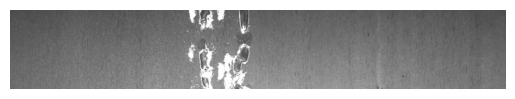

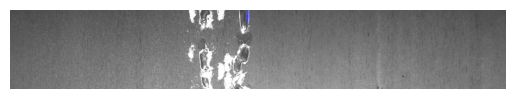

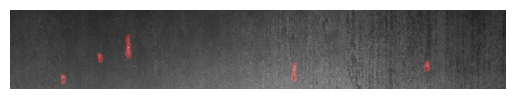

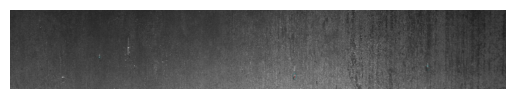

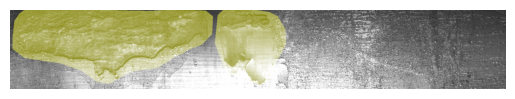

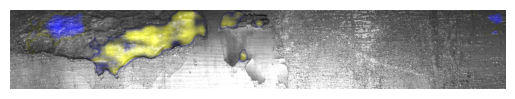

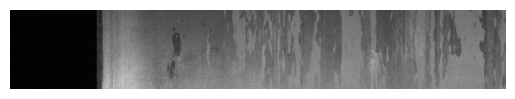

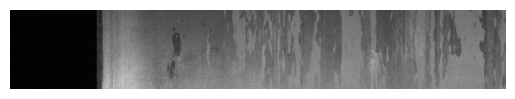

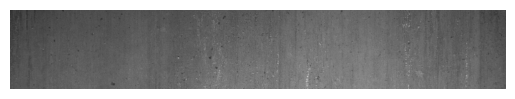

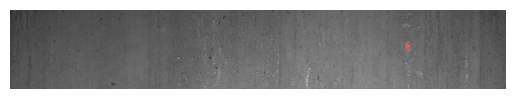

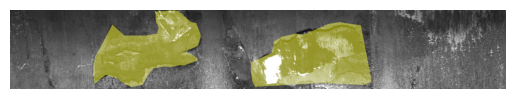

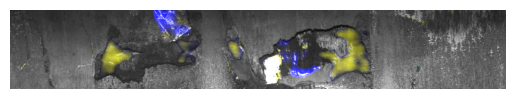

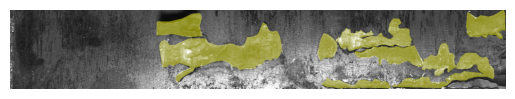

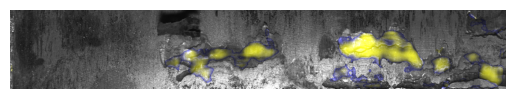

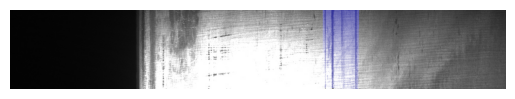

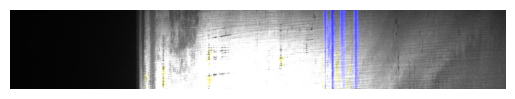

In [40]:
# Example usage: Iterating through the dataloader
i = random.randint(0, len(train_loader)//10)
print(f'Randomly chosen batch: {i + 1}')
mask_colors = [(1, 0, 0), (0, 1, 0), (0, 0, 1), (1, 1, 0)]
for batch_idx, (images, masks) in enumerate(train_loader):
    if batch_idx == i:
        print(f"Batch {batch_idx+1}")
        print(f"Images shape: {images.shape}")
        print(f"Masks shape: {masks.shape}")
        output= model(images.permute(0, 3, 1, 2).to(device))
        output= output.permute(0, 2, 3, 1)
        for img, mask, op in zip(images, masks, output):
            overlay_masks_on_image(img, mask, mask_colors)
            overlay_masks_on_image(img, op.detach(), mask_colors)
        break

Randomly chosen batch: 17
Batch 17
Images shape: torch.Size([8, 256, 1600, 3])
Masks shape: torch.Size([8, 256, 1600, 4])


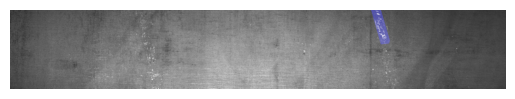

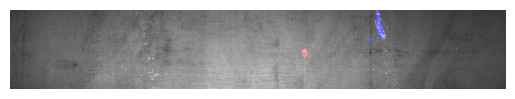

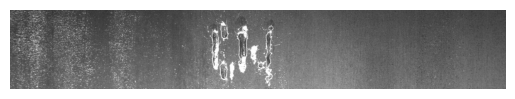

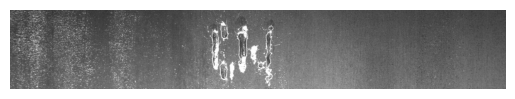

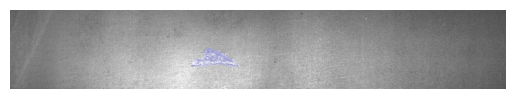

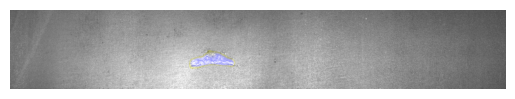

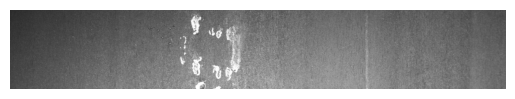

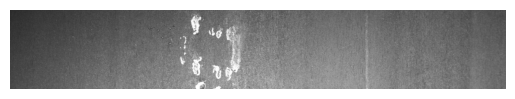

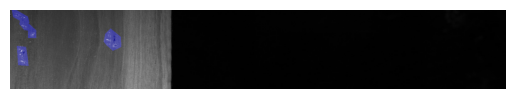

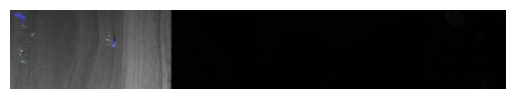

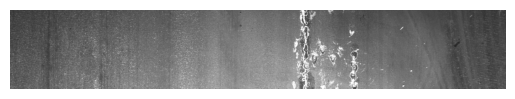

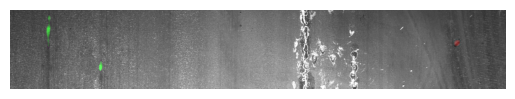

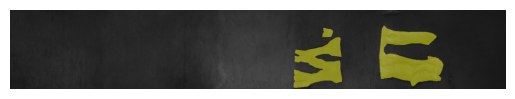

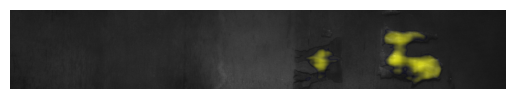

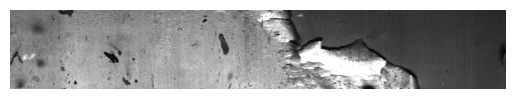

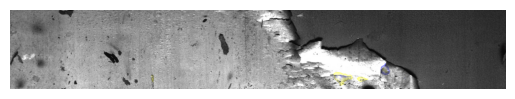

In [41]:
# Example usage: Iterating through the dataloader
i = random.randint(0, len(val_loader)//10)
print(f'Randomly chosen batch: {i + 1}')
mask_colors = [(1, 0, 0), (0, 1, 0), (0, 0, 1), (1, 1, 0)]
for batch_idx, (images, masks) in enumerate(val_loader):
    if batch_idx == i:
        print(f"Batch {batch_idx+1}")
        print(f"Images shape: {images.shape}")
        print(f"Masks shape: {masks.shape}")
        output= model(images.permute(0, 3, 1, 2).to(device))
        output= output.permute(0, 2, 3, 1)
        for img, mask, op in zip(images, masks, output):
            overlay_masks_on_image(img, mask, mask_colors)
            overlay_masks_on_image(img, op.detach(), mask_colors)
        break

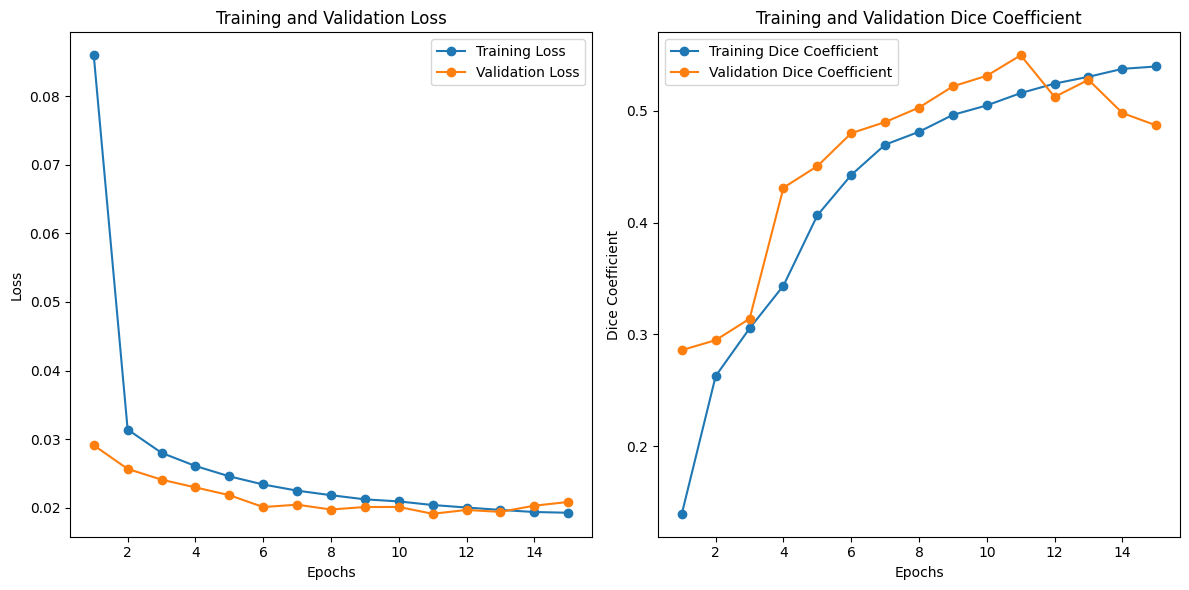

In [42]:
epochs = range(1, len(all_train_losses) + 1)      # Assuming same length for each list

# Create a figure with two subplots
plt.figure(figsize=(12, 6))

# Plot Training and Validation Loss
plt.subplot(1, 2, 1)
plt.plot(epochs, all_train_losses, label='Training Loss', marker='o')
plt.plot(epochs, all_val_losses, label='Validation Loss', marker='o')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()

# Plot Training and Validation Dice Coefficient
plt.subplot(1, 2, 2)
plt.plot(epochs, all_train_dcf, label='Training Dice Coefficient', marker='o')
plt.plot(epochs, all_val_dcf, label='Validation Dice Coefficient', marker='o')
plt.xlabel('Epochs')
plt.ylabel('Dice Coefficient')
plt.title('Training and Validation Dice Coefficient')
plt.legend()

# Adjust layout
plt.tight_layout()
plt.show()


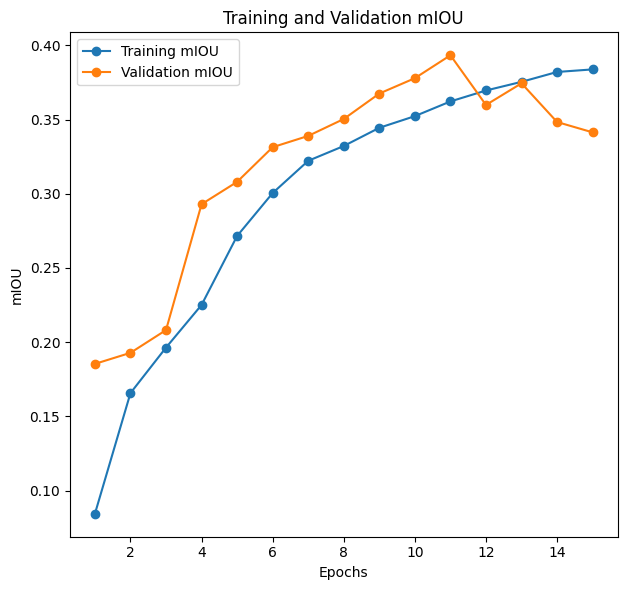

In [43]:
plt.figure(figsize=(12, 6))

# Plot Training and Validation Loss
plt.subplot(1, 2, 1)
plt.plot(epochs, all_train_miou, label='Training mIOU', marker='o')
plt.plot(epochs, all_val_miou, label='Validation mIOU', marker='o')
plt.xlabel('Epochs')
plt.ylabel('mIOU')
plt.title('Training and Validation mIOU')
plt.legend()
plt.tight_layout()
plt.show()